In [1]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Step 2: Load Dataset

df = pd.read_csv("Phishing_Legitimate_full.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Dataset loaded successfully!
Dataset Shape: (10000, 50)

First 5 Rows:


,id,NumDots,SubdomainLevel,PathLevel,UrlLength,NumDash,NumDashInHostname,AtSymbol,TildeSymbol,NumUnderscore,...,IframeOrFrame,MissingTitle,ImagesOnlyInForm,SubdomainLevelRT,UrlLengthRT,PctExtResourceUrlsRT,AbnormalExtFormActionR,ExtMetaScriptLinkRT,PctExtNullSelfRedirectHyperlinksRT,CLASS_LABEL
0,1,3,1,5,72,0,0,0,0,0,...,0,0,1,1,0,1,1,-1,1,1
1,2,3,1,3,144,0,0,0,0,2,...,0,0,0,1,-1,1,1,1,1,1
2,3,3,1,2,58,0,0,0,0,0,...,0,0,0,1,0,-1,1,-1,0,1
3,4,3,1,6,79,1,0,0,0,0,...,0,0,0,1,-1,1,1,1,-1,1
4,5,3,0,4,46,0,0,0,0,0,...,1,0,0,1,1,-1,0,-1,-1,1


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of Rows: 10000
Number of Columns: 50

Column Names:
['id', 'NumDots', 'SubdomainLevel', 'PathLevel', 'UrlLength', 'NumDash', 'NumDashInHostname', 'AtSymbol', 'TildeSymbol', 'NumUnderscore', 'NumPercent', 'NumQueryComponents', 'NumAmpersand', 'NumHash', 'NumNumericChars', 'NoHttps', 'RandomString', 'IpAddress', 'DomainInSubdomains', 'DomainInPaths', 'HttpsInHostname', 'HostnameLength', 'PathLength', 'QueryLength', 'DoubleSlashInPath', 'NumSensitiveWords', 'EmbeddedBrandName', 'PctExtHyperlinks', 'PctExtResourceUrls', 'ExtFavicon', 'InsecureForms', 'RelativeFormAction', 'ExtFormAction', 'AbnormalFormAction', 'PctNullSelfRedirectHyperlinks', 'FrequentDomainNameMismatch', 'FakeLinkInStatusBar', 'RightClickDisabled', 'PopUpWindow', 'SubmitInfoToEmail', 'IframeOrFrame', 'MissingTitle', 'ImagesOnlyInForm', 'SubdomainLevelRT', 'UrlLengthRT', 'PctExtResourceUrlsRT', 'AbnormalExtFormActionR', 'ExtMetaScriptLinkRT', 'PctExtNullSelfRedirectHyperlinksRT', 'CLASS_LABEL']


In [4]:
# Step 3: Dataset Information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 50 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id                                  10000 non-null  int64  
 1   NumDots                             10000 non-null  int64  
 2   SubdomainLevel                      10000 non-null  int64  
 3   PathLevel                           10000 non-null  int64  
 4   UrlLength                           10000 non-null  int64  
 5   NumDash                             10000 non-null  int64  
 6   NumDashInHostname                   10000 non-null  int64  
 7   AtSymbol                            10000 non-null  int64  
 8   TildeSymbol                         10000 non-null  int64  
 9   NumUnderscore                       10000 non-null  int64  
 10  NumPercent                          10000 non-null  int64  
 11  NumQueryComponents   

,id,NumDots,SubdomainLevel,PathLevel,UrlLength,NumDash,NumDashInHostname,AtSymbol,TildeSymbol,NumUnderscore,...,IframeOrFrame,MissingTitle,ImagesOnlyInForm,SubdomainLevelRT,UrlLengthRT,PctExtResourceUrlsRT,AbnormalExtFormActionR,ExtMetaScriptLinkRT,PctExtNullSelfRedirectHyperlinksRT,CLASS_LABEL
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,...,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,2.445100,0.586800,3.300300,70.264100,1.818000,0.138900,0.000300,0.013100,0.32320,...,0.339600,0.03220,0.030400,0.956600,0.020200,0.353300,0.793200,0.173400,0.314100,0.500000
std,2886.89568,1.346836,0.751214,1.863241,33.369877,3.106258,0.545744,0.017319,0.113709,1.11466,...,0.473597,0.17654,0.171694,0.248037,0.820036,0.888908,0.521019,0.755771,0.897843,0.500025
min,1.00000,1.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.00000,...,0.000000,0.00000,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.000000
25%,2500.75000,2.000000,0.000000,2.000000,48.000000,0.000000,0.000000,0.000000,0.000000,0.00000,...,0.000000,0.00000,0.000000,1.000000,-1.000000,-1.000000,1.000000,0.000000,-1.000000,0.000000
50%,5000.50000,2.000000,1.000000,3.000000,62.000000,0.000000,0.000000,0.000000,0.000000,0.00000,...,0.000000,0.00000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.500000
75%,7500.25000,3.000000,1.000000,4.000000,84.000000,2.000000,0.000000,0.000000,0.000000,0.00000,...,1.000000,0.00000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,10000.00000,21.000000,14.000000,18.000000,253.000000,55.000000,9.000000,1.000000,1.000000,18.00000,...,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Missing Values:
id                                    0
NumDots                               0
SubdomainLevel                        0
PathLevel                             0
UrlLength                             0
NumDash                               0
NumDashInHostname                     0
AtSymbol                              0
TildeSymbol                           0
NumUnderscore                         0
NumPercent                            0
NumQueryComponents                    0
NumAmpersand                          0
NumHash                               0
NumNumericChars                       0
NoHttps                               0
RandomString                          0
IpAddress                             0
DomainInSubdomains                    0
DomainInPaths                         0
HttpsInHostname                       0
HostnameLength                        0
PathLength                            0
QueryLength                           0
DoubleSlashInPath      

Target Class Distribution:
CLASS_LABEL
1    5000
0    5000
Name: count, dtype: int64

Target Distribution in Percentage:
CLASS_LABEL
1    50.0
0    50.0
Name: proportion, dtype: float64


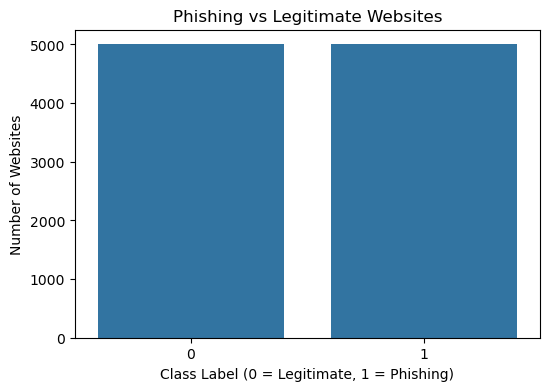

In [5]:
# Step 4: Target Variable Analysis

print("Target Class Distribution:")
print(df["CLASS_LABEL"].value_counts())

print("\nTarget Distribution in Percentage:")
print((df["CLASS_LABEL"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="CLASS_LABEL")

plt.title("Phishing vs Legitimate Websites")
plt.xlabel("Class Label (0 = Legitimate, 1 = Phishing)")
plt.ylabel("Number of Websites")

plt.show()

In [6]:
# Step 5: Data Cleaning

df = df.drop_duplicates().copy()

# Drop ID column because it is an identifier, not a website feature
if "id" in df.columns:
    df.drop(columns=["id"], inplace=True)

# Handle missing values
for col in df.columns:
    if df[col].isnull().any():

        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())

        else:
            mode_values = df[col].mode()

            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values.iloc[0])
            else:
                df[col] = df[col].fillna("Unknown")

print("Data cleaning completed!")

print("New Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())
print("Remaining Duplicate Rows:", df.duplicated().sum())

Data cleaning completed!
New Dataset Shape: (10000, 49)
Remaining Missing Values: 0
Remaining Duplicate Rows: 419


In [7]:
# Verify Target Column

if "CLASS_LABEL" not in df.columns:
    raise ValueError("CLASS_LABEL target column not found!")

print(df["CLASS_LABEL"].value_counts())

CLASS_LABEL
1    5000
0    5000
Name: count, dtype: int64


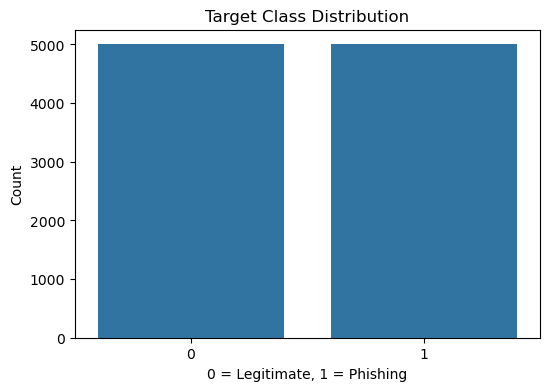

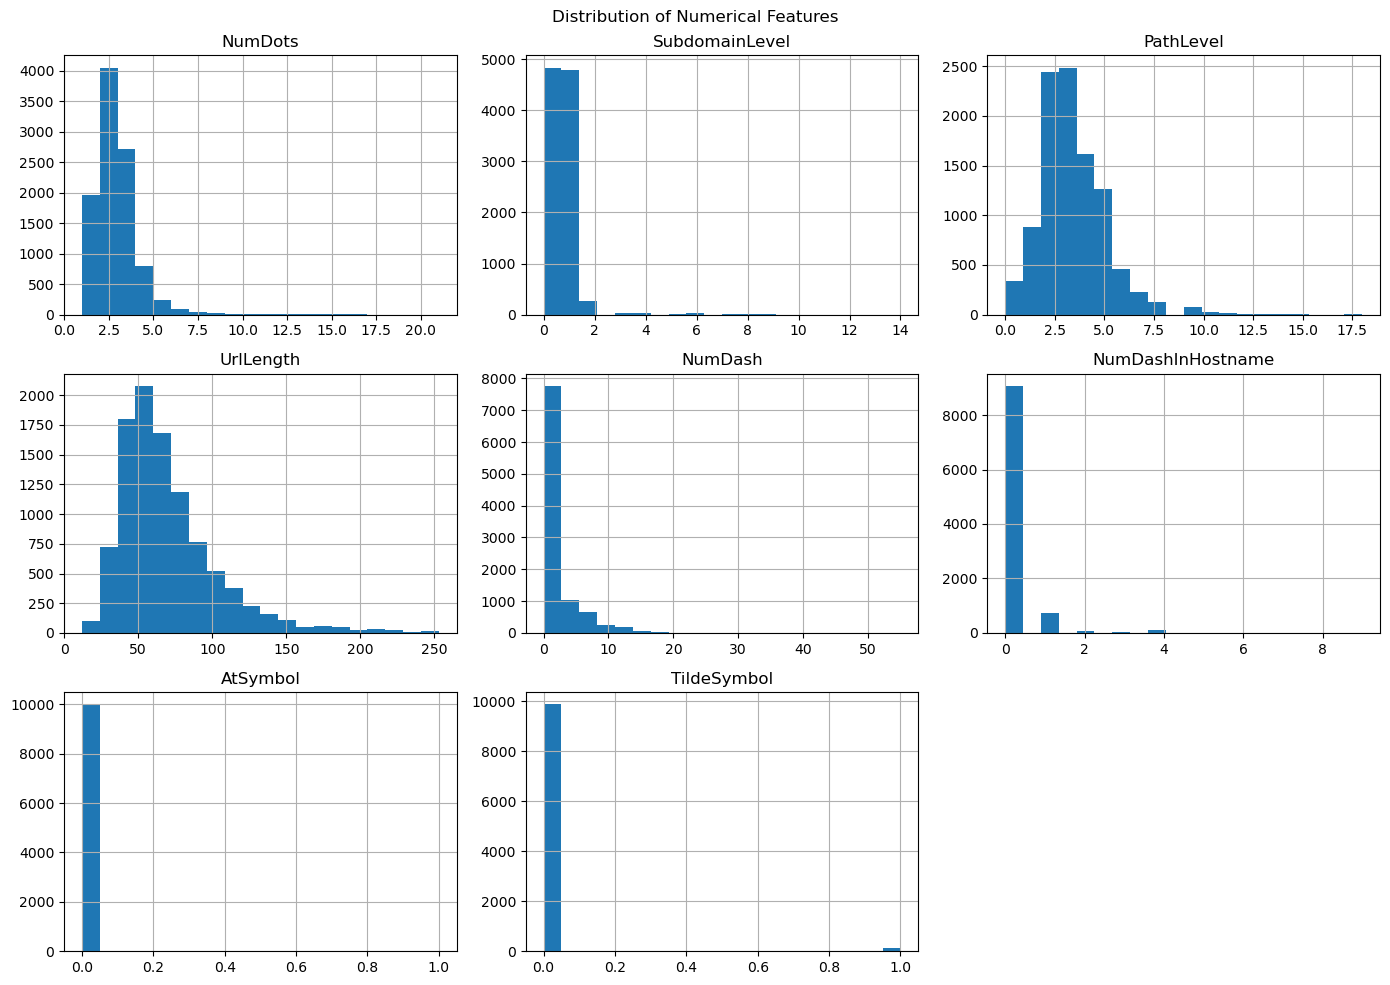

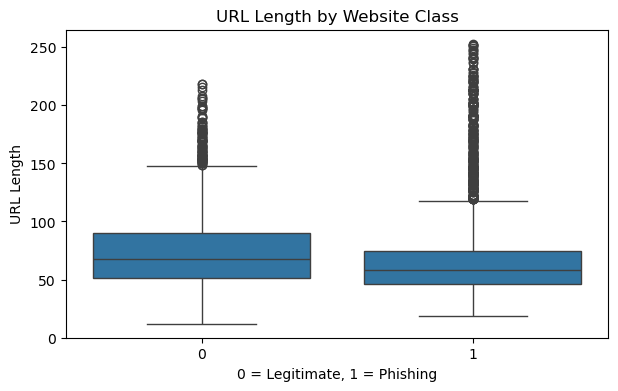

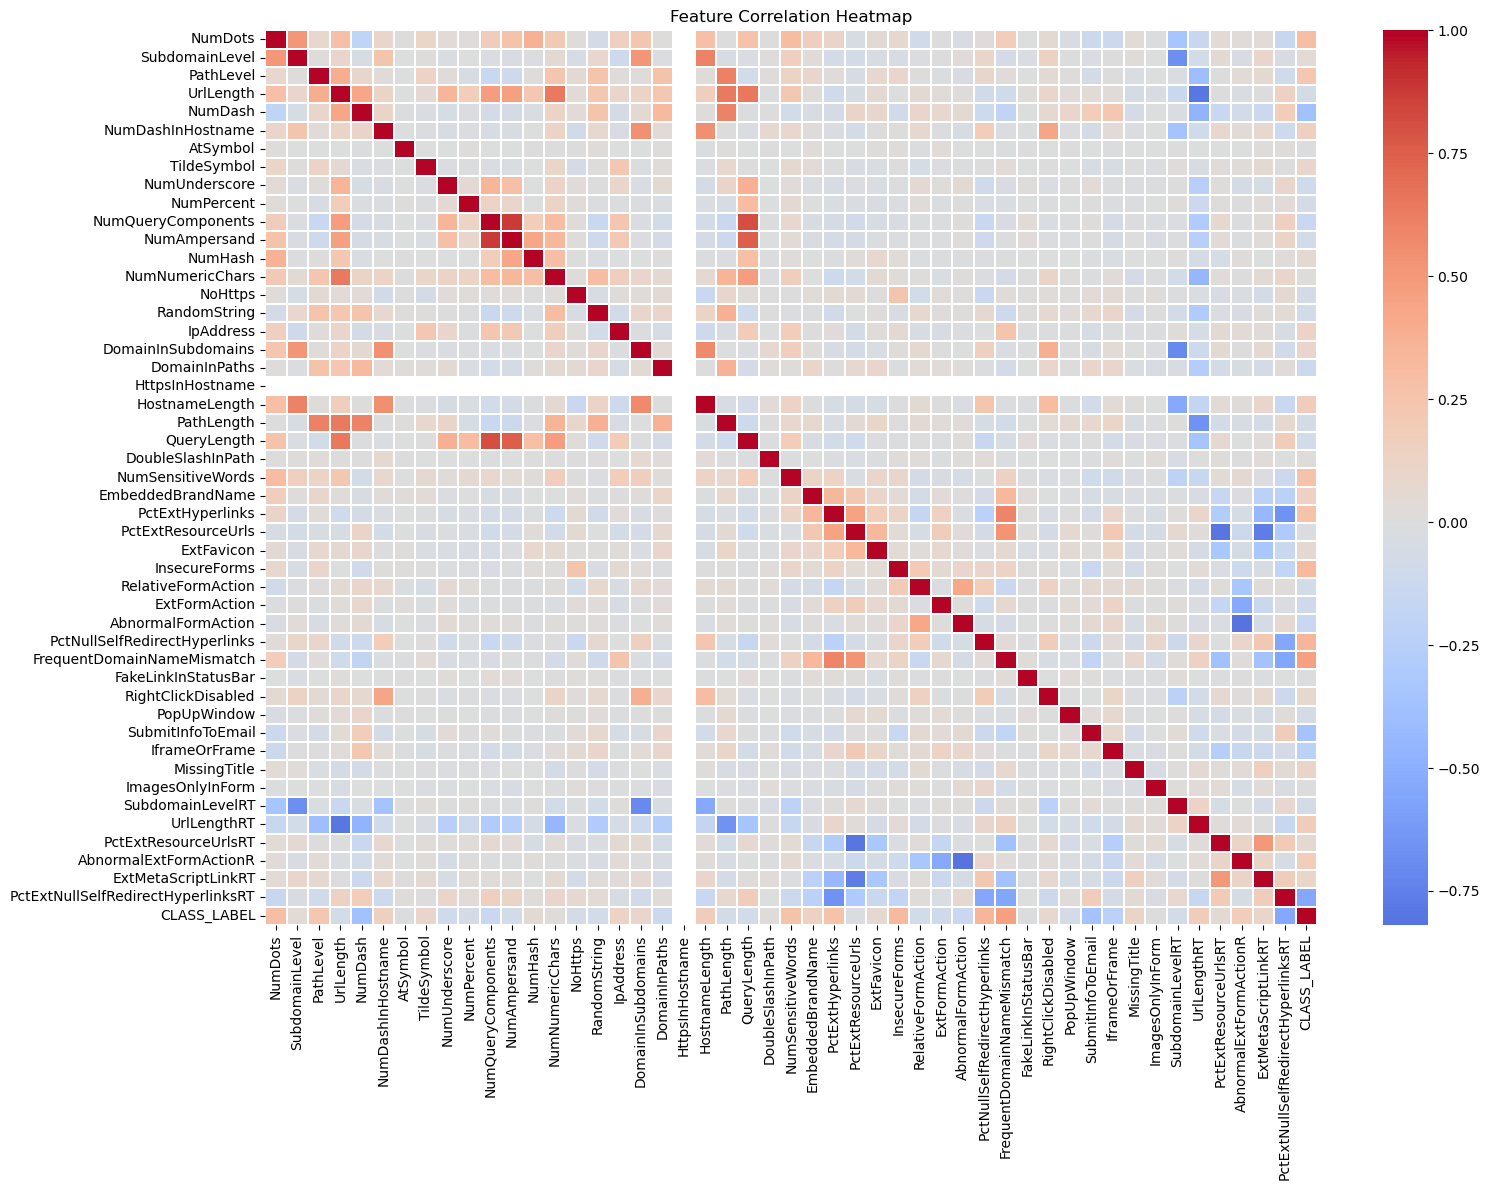

In [8]:
# Target Distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="CLASS_LABEL")

plt.title("Target Class Distribution")
plt.xlabel("0 = Legitimate, 1 = Phishing")
plt.ylabel("Count")

plt.show()

# Histograms of Numerical Features

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

numeric_features = [
    col for col in numeric_cols
    if col != "CLASS_LABEL"
][:8]

df[numeric_features].hist(figsize=(14, 10), bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()

plt.show()

# Boxplot of URL Length by Class

if "UrlLength" in df.columns:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="CLASS_LABEL",
        y="UrlLength"
    )

    plt.title("URL Length by Website Class")
    plt.xlabel("0 = Legitimate, 1 = Phishing")
    plt.ylabel("URL Length")

    plt.show()

# Correlation Heatmap

corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()

plt.show()

In [9]:
# Step 7: Feature Engineering

df_model = df.copy()

# Create a new feature from existing columns
if "NumDots" in df_model.columns and "SubdomainLevel" in df_model.columns:

    df_model["DomainComplexity"] = (
        df_model["NumDots"] + df_model["SubdomainLevel"]
    )

print("New feature created if source columns were available.")

print("Dataset Shape:", df_model.shape)

# Separate Features and Target

X = df_model.drop(columns=["CLASS_LABEL"]).copy()
y = df_model["CLASS_LABEL"].copy()

# Encode target labels
le_y = LabelEncoder()
y = pd.Series(
    le_y.fit_transform(y),
    index=y.index,
    name="CLASS_LABEL"
)

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nEncoded Target Classes:")
print(le_y.classes_)

# Convert categorical columns into numerical columns

X = pd.get_dummies(X, drop_first=True)

# Replace infinite values and handle missing values
X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(X.median(numeric_only=True))
X = X.fillna(0)

print("Features after encoding:", X.shape)

# Feature Selection using SelectKBest

k = min(15, X.shape[1])

selector = SelectKBest(score_func=f_classif, k=k)

X_selected_array = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()].tolist()

X_selected = pd.DataFrame(
    X_selected_array,
    columns=selected_features,
    index=X.index
)

print("Selected Features:")
for feature in selected_features:
    print(feature)

print("\nNumber of Selected Features:", len(selected_features))

New feature created if source columns were available.
Dataset Shape: (10000, 50)
Feature Shape: (10000, 49)
Target Shape: (10000,)

Encoded Target Classes:
[0 1]
Features after encoding: (10000, 49)
Selected Features:
NumDots
PathLevel
NumDash
HostnameLength
NumSensitiveWords
PctExtHyperlinks
InsecureForms
PctNullSelfRedirectHyperlinks
FrequentDomainNameMismatch
SubmitInfoToEmail
IframeOrFrame
UrlLengthRT
AbnormalExtFormActionR
PctExtNullSelfRedirectHyperlinksRT
DomainComplexity

Number of Selected Features: 15


In [10]:
# Step 8: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (8000, 15)
Testing Data Shape: (2000, 15)

Training Target Distribution:
CLASS_LABEL
0    4000
1    4000
Name: count, dtype: int64

Testing Target Distribution:
CLASS_LABEL
0    1000
1    1000
Name: count, dtype: int64


In [11]:
# Step 9: Evaluation Function

results = []

def evaluate(name, model):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Specificity": specificity,
        "AUC": roc_auc_score(y_test, y_prob)
    }

    results.append(metrics)

    print("\nModel:", name)
    print("-" * 45)

    for metric, value in metrics.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    return y_pred


Model: Baseline Random Forest
---------------------------------------------
Accuracy: 0.9760
Precision: 0.9741
Recall: 0.9780
F1: 0.9760
Specificity: 0.9740
AUC: 0.9957


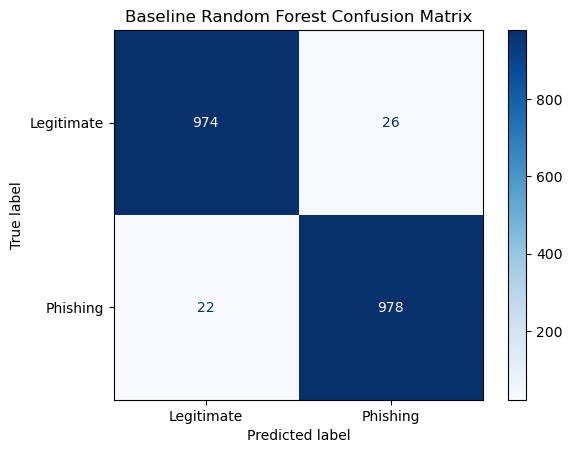


Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.98      0.97      0.98      1000
    Phishing       0.97      0.98      0.98      1000

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



In [12]:
# Baseline Random Forest

baseline_model = RandomForestClassifier(
    random_state=42,
    n_estimators=100
)

y_pred_baseline = evaluate(
    "Baseline Random Forest",
    baseline_model
)

# Baseline Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
)

disp.plot(cmap="Blues")

plt.title("Baseline Random Forest Confusion Matrix")
plt.show()

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_baseline,
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    )
)

In [13]:
# Step 10: Hyperparameter Tuning

n_estimators_values = [50, 100, 200]

max_depth_values = [None, 5, 10]

tuned_models = {}

for n in n_estimators_values:

    for depth in max_depth_values:

        model_name = f"RF_n={n}_depth={depth}"

        model = RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        )

        evaluate(model_name, model)

        tuned_models[model_name] = model

print("\nHyperparameter tuning completed!")
print("Total models evaluated:", len(results))


Model: RF_n=50_depth=None
---------------------------------------------
Accuracy: 0.9775
Precision: 0.9780
Recall: 0.9770
F1: 0.9775
Specificity: 0.9780
AUC: 0.9957

Model: RF_n=50_depth=5
---------------------------------------------
Accuracy: 0.9590
Precision: 0.9448
Recall: 0.9750
F1: 0.9596
Specificity: 0.9430
AUC: 0.9919

Model: RF_n=50_depth=10
---------------------------------------------
Accuracy: 0.9695
Precision: 0.9700
Recall: 0.9690
F1: 0.9695
Specificity: 0.9700
AUC: 0.9954

Model: RF_n=100_depth=None
---------------------------------------------
Accuracy: 0.9760
Precision: 0.9741
Recall: 0.9780
F1: 0.9760
Specificity: 0.9740
AUC: 0.9957

Model: RF_n=100_depth=5
---------------------------------------------
Accuracy: 0.9605
Precision: 0.9484
Recall: 0.9740
F1: 0.9610
Specificity: 0.9470
AUC: 0.9923

Model: RF_n=100_depth=10
---------------------------------------------
Accuracy: 0.9705
Precision: 0.9710
Recall: 0.9700
F1: 0.9705
Specificity: 0.9710
AUC: 0.9956

Model: RF_

Top 10 Important Features:


,Feature,Importance
5,PctExtHyperlinks,0.307828
13,PctExtNullSelfRedirectHyperlinksRT,0.176736
8,FrequentDomainNameMismatch,0.093790
7,PctNullSelfRedirectHyperlinks,0.087143
2,NumDash,0.064148
1,PathLevel,0.049948
6,InsecureForms,0.042823
9,SubmitInfoToEmail,0.037242
3,HostnameLength,0.035633
0,NumDots,0.022451


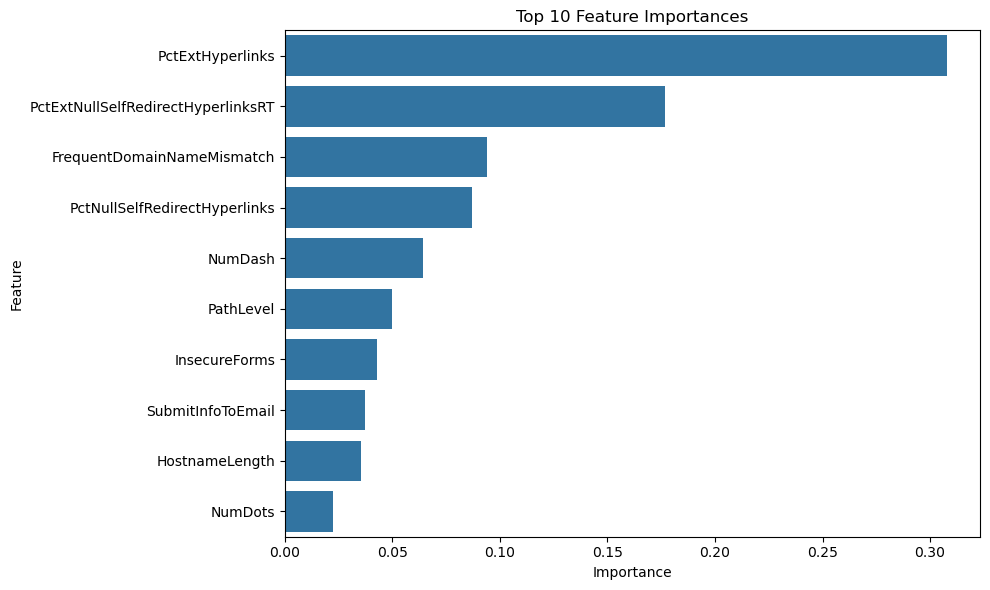

In [14]:
# Feature Importance

importance_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

importance_model.fit(X_train, y_train)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances")
plt.tight_layout()

plt.show()



In [15]:
# Step 11: Compare All Models

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates(
    subset=["Model"],
    keep="last"
)

results_df = results_df.sort_values(
    by="Recall",
    ascending=False
).reset_index(drop=True)

print("Model Comparison:")
display(results_df)

Model Comparison:


,Model,Accuracy,Precision,Recall,F1,Specificity,AUC
0,RF_n=200_depth=None,0.9765,0.974129,0.979,0.976559,0.974,0.995888
1,Baseline Random Forest,0.9760,0.974104,0.978,0.976048,0.974,0.995673
2,RF_n=100_depth=None,0.9760,0.974104,0.978,0.976048,0.974,0.995673
3,RF_n=50_depth=None,0.9775,0.977978,0.977,0.977489,0.978,0.995681
4,RF_n=50_depth=5,0.9590,0.944767,0.975,0.959646,0.943,0.991916
5,RF_n=100_depth=5,0.9605,0.948393,0.974,0.961026,0.947,0.992318
6,RF_n=200_depth=5,0.9595,0.946550,0.974,0.960079,0.945,0.992601
7,RF_n=100_depth=10,0.9705,0.970971,0.970,0.970485,0.971,0.995646
8,RF_n=50_depth=10,0.9695,0.969970,0.969,0.969485,0.970,0.995447
9,RF_n=200_depth=10,0.9725,0.975831,0.969,0.972403,0.976,0.995738


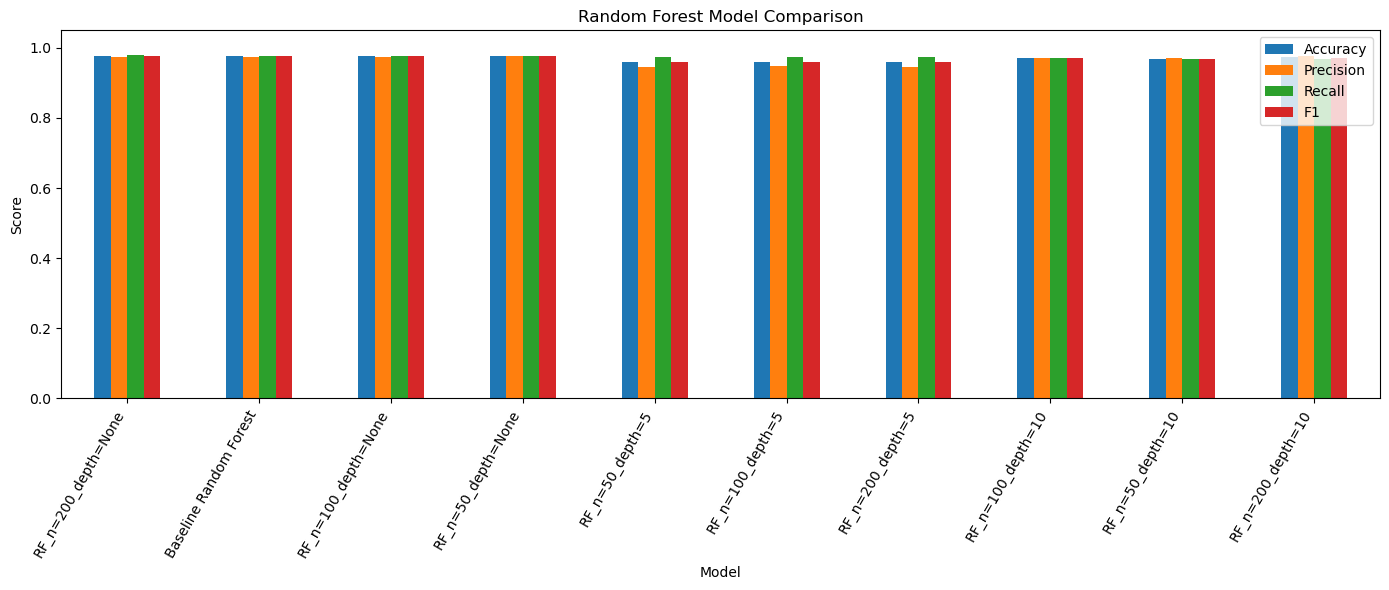

Best Model Name: RF_n=200_depth=None

Best Model Parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Final Model Performance:
              precision    recall  f1-score   support

  Legitimate       0.98      0.97      0.98      1000
    Phishing       0.97      0.98      0.98      1000

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



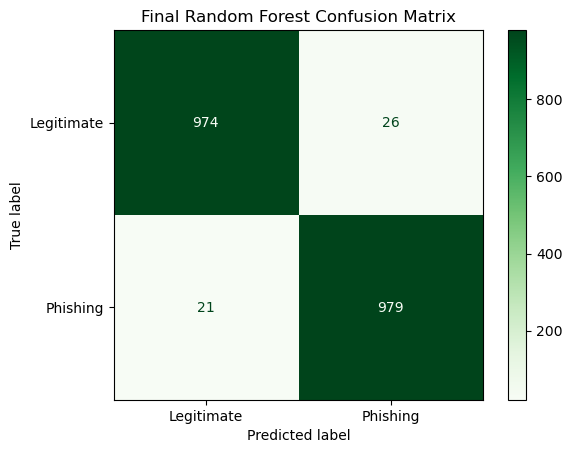

Final Accuracy: 0.9765
Final Precision: 0.9741
Final Recall: 0.979
Final F1-Score: 0.9766
Final Specificity: 0.974
Final ROC-AUC: 0.9959


In [16]:
# Compare Accuracy, Precision, Recall and F1

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]

results_plot = results_df.set_index("Model")[metrics_to_plot]

results_plot.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Random Forest Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()

plt.show()

# Select Best Model

best_model_name = results_df.iloc[0]["Model"]

print("Best Model Name:", best_model_name)

if best_model_name == "Baseline Random Forest":

    final_model = baseline_model

else:

    final_model = tuned_models[best_model_name]

print("\nBest Model Parameters:")
print(final_model.get_params())

# Final Model Evaluation

final_model.fit(X_train, y_train)

y_pred_final = final_model.predict(X_test)

print("Final Model Performance:")
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    )
)

cm_final = confusion_matrix(
    y_test,
    y_pred_final,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Legitimate", "Phishing"]
)

disp.plot(cmap="Greens")

plt.title("Final Random Forest Confusion Matrix")
plt.show()

# Final Model Scores

tn, fp, fn, tp = cm_final.ravel()

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final, zero_division=0)
final_recall = recall_score(y_test, y_pred_final, zero_division=0)
final_f1 = f1_score(y_test, y_pred_final, zero_division=0)
final_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
final_auc = roc_auc_score(
    y_test,
    final_model.predict_proba(X_test)[:, 1]
)

print("Final Accuracy:", round(final_accuracy, 4))
print("Final Precision:", round(final_precision, 4))
print("Final Recall:", round(final_recall, 4))
print("Final F1-Score:", round(final_f1, 4))
print("Final Specificity:", round(final_specificity, 4))
print("Final ROC-AUC:", round(final_auc, 4))

In [17]:
# Step 12: Predict Three New Samples

# Select 3 samples from the test dataset
new_samples = X_test.iloc[:3].copy()

# Modify selected feature values slightly for demonstration
for col in new_samples.columns:

    if pd.api.types.is_numeric_dtype(new_samples[col]):

        new_samples.loc[new_samples.index[0], col] = (
            new_samples[col].median()
        )

print("New Samples:")
display(new_samples)

# Predict classes
new_predictions = final_model.predict(new_samples)

# Convert predictions back to original labels
original_predictions = le_y.inverse_transform(
    new_predictions.astype(int)
)

print("\nPredictions:")

for i, prediction in enumerate(original_predictions, start=1):

    if prediction == 1:
        result = "Phishing Website"
    else:
        result = "Legitimate Website"

    print(f"Sample {i}: {result}")

New Samples:


,NumDots,PathLevel,NumDash,HostnameLength,NumSensitiveWords,PctExtHyperlinks,InsecureForms,PctNullSelfRedirectHyperlinks,FrequentDomainNameMismatch,SubmitInfoToEmail,IframeOrFrame,UrlLengthRT,AbnormalExtFormActionR,PctExtNullSelfRedirectHyperlinksRT,DomainComplexity
7919,3.0,4.0,7.0,24.0,0.0,0.093407,1.0,0.130631,0.0,0.0,1.0,-1.0,1.0,0.0,3.0
911,3.0,4.0,0.0,24.0,0.0,0.000000,1.0,1.000000,0.0,0.0,0.0,0.0,1.0,-1.0,3.0
6631,1.0,5.0,7.0,10.0,0.0,0.229730,1.0,0.130631,0.0,0.0,1.0,-1.0,1.0,0.0,1.0



Predictions:
Sample 1: Legitimate Website
Sample 2: Phishing Website
Sample 3: Legitimate Website
